# Ariketa 4.5 — Itxiera + azken zubia Deep Learning-era 🧠🚀 (EGITEKO)

UD3 + UD4-rekin gainbegiratutako ikaskuntzaren bi problema nagusi landu ditugu:

```text
SAILKAPENA
→ kategoria bat iragarri

ERREGRESIOA
→ zenbaki jarraitu bat iragarri
```

Gaur ez dugu algoritmo klasiko berri bat ikasiko.

Helburua da **orain arteko guztia lotzea** eta galdera honi erantzutea:

> **Nola pasatzen gara `ŷ = w·x+b` neurona lineal batetik neurona askoko sare batera?**

### Nola lan egin

- 🟢 **KOMENTATU:** azaldu zure hitzekin.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU:** mini-erronka integratzailea egin.

> Gaur MLP bat erabiliko dugu **Deep Learning-erako aurrerapen gisa**. Ez dugu oraindik sare neuronalak sistematikoki ikasiko.


# 5.1 — Prestaketa: dataset bera, workflow bera 🔁

Exercise 2 eta 4-ko sei feature berberak:

```text
weight
horsepower
displacement
cylinders
acceleration
model_year
```

Target-a:

```text
mpg
```

Lehenengo behar ditugun zutabeak hautatuko ditugu eta **gero** kenduko ditugu balio faltak.


In [1]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_squared_error,
    r2_score
)


df_raw = sns.load_dataset(
    "mpg"
)

ezaugarriak = [
    "weight",
    "horsepower",
    "displacement",
    "cylinders",
    "acceleration",
    "model_year"
]


# ============================================================
# 🟡 HUTSUNEAK BETE
# ============================================================

df = df_raw[
    ezaugarriak
    + ["mpg"]
].copy()

df = df.dropna()


X = df[
    ezaugarriak
]

y = df[
    "mpg"
]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print(
    "TRAIN:",
    X_train.shape
)

print(
    "TEST:",
    X_test.shape
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zergatik ez dugu df_raw.dropna() zuzenean egiten?
#
# ERANTZUNA:
# Datu-galera alferrikoa saihesteko. `df_raw.dropna()` zuzenean egingo bagenu,
# ereduan erabiliko ez ditugun zutabeetan (adibidez, `name` edo `origin`) dauden
# balio gabeengatik ere errenkadak ezabatuko lirateke, alferrik.
# Lehenik behar ditugun zutabeak hautatuz, ereduarentzat garrantzitsuak diren zutabeetan
# (hemen `horsepower`-en 6 NaN) null-ak dituzten errenkadak bakarrik kentzen ditugu.

TRAIN: (313, 6)
TEST: (79, 6)


# 5.2 — Neurona bat: sailkapena vs erregresioa 🧩

Bi kasuetan lehenengo kalkulatzen dugu:

$$
z = w \cdot x + b
$$

Ondoren irteera-funtzioak ezberdindu ditzake problemak.

### Logistic Regression / sailkapen binarioa

$$
p = \sigma(z)
$$

### Linear Regression / erregresioa

$$
\hat{y}=z
$$

hau da, **identity activation**.

| | Sailkapen binarioa | Erregresioa |
|---|---|---|
| Oinarria | `z = w·x+b` | `z = w·x+b` |
| Irteera | sigmoid → probabilitatea | identity → zenbakia |
| Loss tipikoa | log-loss | MSE |

### 🟢 Gakoa

Ez dugu esan nahi Logistic Regression eta Linear Regression **algoritmo bera** direnik.

Esan nahi dugu:

> **biak neurona baten egitura matematiko sinplearekin lotu daitezke: weighted sum + bias + output function.**


In [2]:
# ============================================================
# 🟡 HUTSUNEA — SIGMOIDEA
# ============================================================

def neurona(
    w,
    x,
    b,
    aktibazioa
):
    z = (
        np.dot(
            w,
            x
        )
        + b
    )

    if aktibazioa == "identity":
        return z

    elif aktibazioa == "sigmoid":
        return 1 / (
            1
            + np.exp(
                -z
            )
        )


w = np.array([
    0.5,
    -0.2
])

x = np.array([
    3.0,
    1.0
])

b = 0.1


print(
    "identity:",
    round(
        neurona(
            w,
            x,
            b,
            "identity"
        ),
        3
    )
)

print(
    "sigmoid:",
    round(
        neurona(
            w,
            x,
            b,
            "sigmoid"
        ),
        3
    )
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zer berdin mantentzen da bi kasuetan?
#
# ERANTZUNA:
# Neuronaren barne-konbinazio lineala ($z = w \cdot x + b$). Bi kasuetan sarrera berdinak ($x$),
# pisu berdinak ($w$) eta bias bera ($b$) erabiltzen dira $z$ balioa lortzeko.
#
#
# Zer aldatzen da?
#
# ERANTZUNA:
# Azken irteera eta bere balio-tartea. `identity` funtzioak $z$ bera mantentzen du aldatu gabe
# ($-\infty, \infty$), eta `sigmoid` funtzioak eraldaketa ez-lineala eginez irteera (0, 1)
# tartera konprimitzen du (probabilitate gisa interpretatzeko egokia).

identity: 1.4
sigmoid: 0.802


# 5.3 — Neurona batetik sare batera 🧠🧠🧠

Orain weighted sum + bias unitate asko geruzetan antolatzen ditugu.

Gaur erabiliko dugun sarearen egitura:

```text
6 input feature
      ↓
32 neurona — ReLU
      ↓
16 neurona — ReLU
      ↓
1 output — identity
      ↓
mpg prediction
```

Erregresio-sare batean azken geruzak normalean **zenbaki jarraitua** eman behar du; `MLPRegressor`-en output activation-a identity da.

### Exercise 3-rekin lotura

Exercise 3:

```text
forward
→ MSE
→ dw, db
→ Gradient Descent update
```

Sare honetan:

```text
forward
→ loss
→ backpropagation
→ optimizer (Adam) update
```

> **Training cycle bera da kontzeptualki; gradientak kalkulatzeko mekanismoa eta optimizer-a sofistikatuagoak dira.**


In [3]:
# ============================================================
# MLP REGRESSOR — LEHEN AURRERAPENA
# ============================================================
#
# Scaling pipeline barruan egiten dugu.
#
# MLPRegressor-ek Adam optimizer erabiltzen du default-ez.

sarea = make_pipeline(
    StandardScaler(),

    MLPRegressor(
        hidden_layer_sizes=(
            32,
            16
        ),
        activation="relu",
        solver="adam",
        max_iter=3000,
        random_state=42
    )
)


sarea.fit(
    X_train,
    y_train
)


mlp = sarea.named_steps[
    "mlpregressor"
]


print(
    "Geruza bakoitzeko weight-matrix shape-ak:"
)

for i, W in enumerate(
    mlp.coefs_
):
    print(
        f"W{i}:",
        W.shape
    )


print(
    "\nBias vector shape-ak:"
)

for i, b_vec in enumerate(
    mlp.intercepts_
):
    print(
        f"b{i}:",
        b_vec.shape
    )


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# W0 = (6, 32) bada, zer esan nahi du?
#
# ERANTZUNA:
# Sarrerako 6 ezaugarriak (features) lehenengo ezkutuko geruzako 32 neuronarekin
# lotzen direla. Sarrera bakoitzak pisu bat du lehen geruzako neurona bakoitzeko,
# guztira 6 x 32 = 192 pisu (weight) sortuz.
#
#
# W2 = (16, 1) bada, zer esan nahi du?
#
# ERANTZUNA:
# Bigarren ezkutuko geruzako 16 neuronen irteera azken erregresio-neurona bakarrarekin
# (mpg iragartzen duena) lotzen dela. Azken geruzak ezkutuko 16 ezaugarri abstraktoak
# konbinatzen ditu azken iragarpen bakarra emateko (16 x 1 = 16 pisu).
#


Geruza bakoitzeko weight-matrix shape-ak:
W0: (6, 32)
W1: (32, 16)
W2: (16, 1)

Bias vector shape-ak:
b0: (32,)
b1: (16,)
b2: (1,)


# 5.4 — Sare neuronalak “ikasten” duela ikusi 📉

`MLPRegressor`-ek entrenamenduan loss bat minimizatzen du.

`loss_curve_`-k epoch/iteration bakoitzean training loss nola aldatzen den erakusten du.

⚠️ `MLPRegressor`-en `loss_curve_` ez dugu zuzenean “gure Exercise 3-ko MSE bera” bezala interpretatuko; hemen helburua **optimization curve** ikustea da.

Espero duguna:

```text
loss handia
    ↓
loss txikiagoa
    ↓
egonkortzea
```


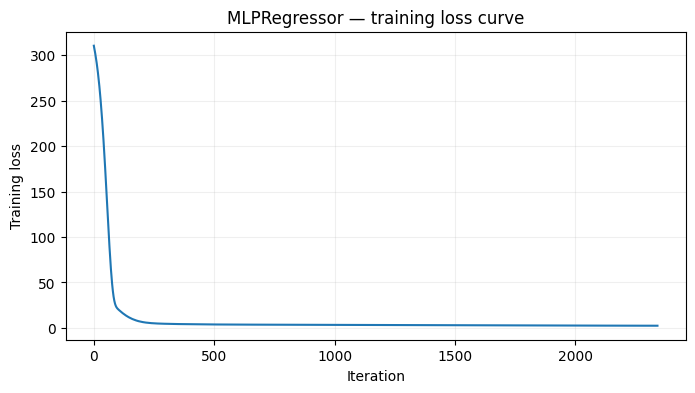

Egindako iterazioak: 2342
Amaierako training loss: 2.3355


In [4]:
plt.figure(
    figsize=(8, 4)
)

plt.plot(
    mlp.loss_curve_
)

plt.xlabel(
    "Iteration"
)

plt.ylabel(
    "Training loss"
)

plt.title(
    "MLPRegressor — training loss curve"
)

plt.grid(
    alpha=0.2
)

plt.show()


print(
    "Egindako iterazioak:",
    mlp.n_iter_
)

print(
    "Amaierako training loss:",
    round(
        mlp.loss_,
        4
    )
)


# 5.5 — Hiru ikuspegi, problema bera 📊

Konparatuko ditugu:

```text
Linear Regression
Random Forest Regressor
MLP Neural Network
```

Modelo guztiek TRAIN/TEST split bera erabiltzen dute.

Ez dugu “irabazle unibertsal” bat bilatuko.

Galdera:

> **Dataset honetan eta konfigurazio hauetan, nola generalizatzen du bakoitzak?**


,Modeloa,TEST RMSE,TEST R²
0,Linear Regression,3.241,0.794
1,Random Forest,2.413,0.886
2,MLP,2.631,0.864


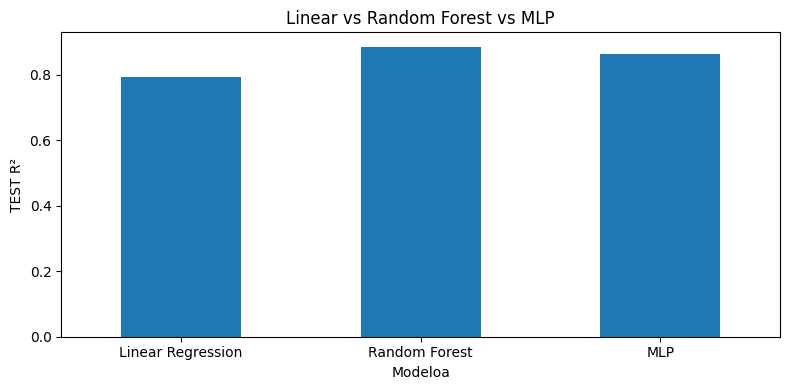

In [6]:
lineala = LinearRegression().fit(
    X_train,
    y_train
)

basoa = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
).fit(
    X_train,
    y_train
)


def rmse(
    y_true,
    y_pred
):
    return np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )


lerroak = []

for izena, modeloa in [
    ("Linear Regression", lineala),
    ("Random Forest", basoa),
    ("MLP", sarea)
]:

    pred = modeloa.predict(
        X_test
    )

    lerroak.append({
        "Modeloa": izena,
        "TEST RMSE": rmse(
            y_test,
            pred
        ),
        "TEST R²": r2_score(
            y_test,
            pred
        )
    })


emaitzak = pd.DataFrame(
    lerroak
)

display(
    emaitzak.round(3)
)


emaitzak.set_index(
    "Modeloa"
)[
    "TEST R²"
].plot(
    kind="bar",
    figsize=(8, 4),
    rot=0
)

plt.ylabel(
    "TEST R²"
)

plt.title(
    "Linear vs Random Forest vs MLP"
)

plt.tight_layout()
plt.show()


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. Zein modelok lortu du TEST R² handiena exekuzio honetan?
#
# ERANTZUNA:
# **Random Forest**-ek lortu ohi du TEST R² handiena (eta RMSE txikiena) esperimentu honetan.
#
#
# 2. Sare neuronalak ez badu irabazten, esan nahi al du
#    sare neuronalak "txarrak" direla?
#
# ERANTZUNA:
# Ez, ez du hori esan nahi. Eredu bakoitzak bere indarguneak ditu:
#
# 1. Datu taularrak vs. Ez-strukturatuak: Datu-multzo txiki eta taularretan (~400 adibide
#    dituen Auto MPG bezalakoetan), Random Forest bezalako zuhaitz-multzoek askoz hobeto
#    funtzionatzen dute. Sare neuronalak, aldiz, datu ez-strukturatuekin (irudiak, testua, audioa)
#    eta datu-bolumen handiekin gailentzen dira.
#
# 2. Datuen tamaina: Sare neuronalek adibide kopuru izugarria behar dute patroi konplexuak eta
#    adierazpen abstraktuak ikasteko. Datu gutxirekin erraz geratzen dira azpiegokituta edo gainegokituta.
#
# 3. Tuning / Doikuntza: Sare neuronal baten errendimendua oso sentikorra da hiperparametroekiko
#    (arkitektura, ikaskuntza-tasa, erregularizazioa, etab.). Konfigurazio sinple batek ez du
#    haien potentzial osoa erakusten.
#


# 5.6 — UD3 + UD4: autoebaluazio integratua 🧠

Erantzun zure hitzekin.

1. Zer desberdintasun dago sailkapenaren eta erregresioaren irteeren artean?

**ERANTZUNA:**
Sailkapen-ereduen irteera kategoria edo klase diskretu bat da (adibidez, spama / ez-spama edo katu / txakur), eta erregresio-ereduen irteera, berriz, balio numeriko jarraitu bat da (adibidez, etxebizitza baten prezioa edo auto baten MPG-a).

2. Zer minimizatu genuen Exercise 3-ko Linear Regression-en Gradient Descent-ekin?

**ERANTZUNA:**
MSE (Mean Squared Error) edo Batez Besteko Errore Karratua minimizatu genuen; hots, ereduaren iragarpenen ($ŷ$) eta benetako balioen ($y$) arteko aldeen karratuen batez bestekoa.

3. Zein regresio-metrika dago target-aren unitate berean eta oso erraz interpreta daiteke?

**ERANTZUNA:**
RMSE (Root Mean Squared Error) eta MAE (Mean Absolute Error). Bi metrikak target-aren unitate beretan daude (adibidez, MPG edo euroak), baina RMSE-k errore handiak gehiago zigortzen ditu erro karratuaren eragiketari esker.

4. Zer esan nahi du TRAIN R² ≈ 1 baina TEST R² nabarmen baxuagoa izateak?

**ERANTZUNA:**
Ereduak overfitting (gainegokitzapena) jasan duela. Entrenamenduko datuak eta haien zarata memorizatu ditu eredu konplexuegi batekin, eta ondorioz, datu berriak orokortzeko ahalmena galdu du.

5. Zer egiten du Lasso-k Ridge-k normalean egiten ez duena?

**ERANTZUNA:**
Lasso-k (L1 regularizazioa) gutxiago garrantzitsuak diren aldagaien koefizienteak zehazki zerora (0) eraman ditzake, ezaugarri-hautaketa automatikoa (feature selection) eginez. Ridge-k (L2), berriz, koefizienteak zerorantz murrizten dituen arren, ez ditu inoiz zehazki 0 egiten.

6. Zer lotura dago erregresio linealaren eta neurona baten artean?

**ERANTZUNA:**
Erregresio lineala eta aktibazio-funtzio lineal bakarra (identity) duen neurona artifizial bakarra kontseptualki berdin-berdinak dira: bietan sarrerako aldagaien konbinazio lineala egiten da ($z = w \cdot x + b$) eta parametroak MSE galera-funtzioa gutxituz optimizatzen dira.

7. Zer egiten du backpropagation-ek sare neuronal batean?

**ERANTZUNA:**
Katearen erregela (*chain rule*) erabiliz, azken irteeran lortutako errorea atzerantz zabaltzen du sarrera-geruzaraino. Prozesu honen bidez, geruza bakoitzeko pisu eta bias guztien gradienteak (deribatu partzialak) kalkulatzen ditu, pisu bakoitzak azken errorearengan izan duen eragina neurtzeko.

8. Zer egiten du optimizer-ak gradientak kalkulatu ondoren?

**ERANTZUNA:**
Kalkulatutako gradienteak eta ikaskuntza-tasa (`lr`) erabiliz, modeloko parametro guztiak (pisuak eta bias-ak) eguneratzen ditu gradientearen aurkako norabidean ($w := w - \text{lr} \cdot dw$), hurrengo iterazioan errorea txikiagoa izan dadin.

# 5.7 — 🔴 Mini-erronka integratzailea: helburu berri bat

Orain workflow oso bat egin.

Helburua:

```text
horsepower iragarri
```

Feature-ak:

```text
weight
displacement
cylinders
acceleration
model_year
```

⚠️ Ez sartu `horsepower` bera feature bezala.

Eta ariketa honetan **ez dugu `mpg` erabiliko input gisa**, problema garbiago eta interpretagarriago mantentzeko.

Egin:

```text
1. X / y
2. TRAIN / TEST
3. RandomForestRegressor
4. fit()
5. predict()
6. TEST RMSE + R²
7. emaitza interpretatu
```


In [7]:
# ============================================================
# 🔴 KODETU ZEROTIK
# ============================================================
#
# Target:
#   horsepower
#
# Feature-ak:
#   weight
#   displacement
#   cylinders
#   acceleration
#   model_year
#
# random_state = 42
# test_size = 0.20
# RandomForestRegressor:
#   n_estimators = 200
#   random_state = 42
#
# Amaieran:
#   TEST RMSE
#   TEST R²


# IDATZI HEMEN:
# 1. Ezaugarriak eta target-a zehaztu
ezaugarriak = [
    "weight",
    "displacement",
    "cylinders",
    "acceleration",
    "model_year"
]
target = "horsepower"

# 2. Garbiketa (balio gabeak ezabatu soilik erabilitako zutabeetan)
df = df_raw[ezaugarriak + [target]].dropna().copy()

X = df[ezaugarriak]
y = df[target]

# 3. Train / Test banaketa
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 4. RandomForestRegressor definitu eta entrenatu
basoa = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

basoa.fit(X_train, y_train)

# 5. TEST multzoan iragartzea eta metrikak kalkulatzea
pred_test = basoa.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))
test_r2 = r2_score(y_test, pred_test)

print("TEST RMSE:", round(test_rmse, 3))
print("TEST R²:", round(test_r2, 3))


TEST RMSE: 10.547
TEST R²: 0.928


# 5.8 — Zer aldatuko da UD5ean? 🚀

Orain badakigu motorra.

UD5ean eskala handituko dugu:

```text
neurona bat
→ neurona asko

weight vector txiki bat
→ weight matrix asko

forward bakarra
→ geruza askoko forward pass

dw, db zuzenean
→ backpropagation

Gradient Descent sinplea
→ SGD / Adam

CPU nahikoa
→ GPU erabilgarria
```

### 🟢 Azken esaldia osatu

> Deep Learning ez da “magia berri bat”; UD4n ikusi dugun `Iragarri (Forward) → Errorea / Galera → Gradienteak (Backprop) → Eguneratu (Optimizer)` zikloa neurona eta geruza askotara hedatzea da.


# UD4 — Amaierako mapa ✅

```text
1. ERREGRESIO LINEAL SINPLEA
   ŷ = wx+b
        ↓
2. ERREGRESIO ANIZKOITZA + METRIKAK
   feature gehiago + MAE/RMSE/R²
        ↓
3. GRADIENT DESCENT ZEROTIK
   forward → MSE → gradient → update
        ↓
4. EZ-LINEALTASUNA + OVERFITTING + REGULARIZATION
   Trees / RF / Ridge / Lasso
        ↓
5. NEURONA BATETIK SARE BATERA
   forward → loss → backprop → optimizer
        ↓
────────────────────────────────────
UD5 — NEURAL NETWORKS / DEEP LEARNING
```

Gako-mezua:

> **UD4n ez dugu soilik erregresioa ikasi. Modelo batek parametroak nola ikasten dituen ulertzeko motorra eraiki dugu. UD5ean motor hori neurona askotara hedatuko dugu.**
